In [2]:
import glob
import os
import tarfile
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import signal, stats

# Use specparam if available, fallback to fooof
try:
    from specparam import SpectralModel as FOOOF
except ImportError:
    from fooof import FOOOF

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")

# Standard 10-20 cortical lobe mapping for 62-channel MPI-LEMON EEG
REGION_MAP = {
    "Frontal": ["Fp1", "Fp2", "AF3", "AF4", "AF7", "AF8", "AFz", "F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8", "Fz"],
    "Central": ["FC1", "FC2", "FC3", "FC4", "FC5", "FC6", "FCz", "C1", "C2", "C3", "C4", "C5", "C6", "Cz", "CP1", "CP2", "CP3", "CP4", "CP5", "CP6", "CPz"],
    "Parietal": ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "Pz", "PO3", "PO4", "PO7", "PO8", "POz"],
    "Occipital": ["O1", "O2", "Oz"],
    "Temporal": ["FT7", "FT8", "T7", "T8", "TP7", "TP8"]
}

C:\Users\Alper\AppData\Local\Temp\ipykernel_36568\3570726327.py:20: DeprecationWarning: 
The `fooof` package is being deprecated and replaced by the `specparam` (spectral parameterization) package.
This version of `fooof` (1.1) is fully functional, but will not be further updated.
New projects are recommended to update to using `specparam` (see Changelog for details).
  from fooof import FOOOF


In [3]:
def compute_irasa_exponent(data, sfreq, fmin=2.0, fmax=40.0, hset=np.arange(1.1, 1.95, 0.05)):
    """
    Pure SciPy implementation of IRASA (Wen & Liu, 2016).
    Isolates the aperiodic 1/f spectrum via geometric mean of up/down-sampled auto-spectra.
    """
    nperseg = int(2 * sfreq)
    freqs, _ = signal.welch(data, fs=sfreq, window="hamming", nperseg=nperseg, axis=-1)
    freq_mask = (freqs >= fmin) & (freqs <= fmax)
    freqs_cropped = freqs[freq_mask]

    psds_irasa = []
    for h in hset:
        q = 1000
        p_up = int(np.round(h * q))
        p_down = int(np.round((1.0 / h) * q))

        sig_up = signal.resample_poly(data, p_up, q, axis=-1)
        sig_down = signal.resample_poly(data, p_down, q, axis=-1)

        _, psd_up = signal.welch(sig_up, fs=sfreq * h, window="hamming", nperseg=int(nperseg * h), axis=-1)
        _, psd_down = signal.welch(sig_down, fs=sfreq / h, window="hamming", nperseg=int(nperseg / h), axis=-1)

        f_up = np.linspace(0, (sfreq * h) / 2, psd_up.shape[-1])
        f_down = np.linspace(0, (sfreq / h) / 2, psd_down.shape[-1])

        psd_up_interp = np.interp(freqs_cropped, f_up, np.mean(psd_up, axis=0))
        psd_down_interp = np.interp(freqs_cropped, f_down, np.mean(psd_down, axis=0))

        psds_irasa.append(np.sqrt(psd_up_interp * psd_down_interp))

    aperiodic_psd = np.median(psds_irasa, axis=0)
    slope, _, r_val, _, _ = stats.linregress(np.log10(freqs_cropped), np.log10(aperiodic_psd))
    return -slope, r_val**2


def extract_dominant_peak(peaks, f_low, f_high):
    """Returns Center Frequency (CF) and Aperiodic-Adjusted Power (PW) for the strongest peak in a band."""
    if peaks.ndim == 1 and peaks.size > 0:
        peaks = peaks.reshape(1, -1)
    elif peaks.size == 0:
        return np.nan, np.nan

    band_peaks = peaks[(peaks[:, 0] >= f_low) & (peaks[:, 0] <= f_high)]
    if len(band_peaks) == 0:
        return np.nan, np.nan

    best_idx = np.argmax(band_peaks[:, 1])
    return band_peaks[best_idx, 0], band_peaks[best_idx, 1]


def process_subject_archive(tar_path, extraction_dir, fmin=2.0, fmax=40.0):
    """
    Extracts Eyes-Closed resting-state EEG from an MPI-LEMON archive and computes:
    - Global & Regional 1/f exponents (specparam/FOOOF fixed mode)
    - Goodness-of-fit (R^2) comparison between 'fixed' and 'knee' modes
    - IRASA 1/f exponent
    - Periodic peak parameters (Theta, Alpha, Beta)
    """
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(path=extraction_dir)

    set_files = glob.glob(os.path.join(extraction_dir, "**", "*_EC.set"), recursive=True)
    if not set_files:
        return None

    raw = mne.io.read_raw_eeglab(set_files[0], preload=True)
    sfreq = raw.info["sfreq"]
    spectrum = raw.compute_psd(method="welch", fmin=fmin, fmax=fmax, n_fft=int(2 * sfreq), window="hamming")
    freqs = spectrum.freqs
    psds = spectrum.get_data()
    avg_psd = np.mean(psds, axis=0)

    # 1. Fixed Mode Parameterization (aligned with Crespo-Garcia et al., 2026)
    fm_fixed = FOOOF(peak_width_limits=[1.0, 6.0], max_n_peaks=6, min_peak_height=0.05, peak_threshold=1.5, aperiodic_mode="fixed", verbose=False)
    fm_fixed.fit(freqs, avg_psd, freq_range=[fmin, fmax])

    # 2. Knee Mode Parameterization (for R^2 comparison)
    fm_knee = FOOOF(peak_width_limits=[1.0, 6.0], max_n_peaks=6, min_peak_height=0.05, peak_threshold=1.5, aperiodic_mode="knee", verbose=False)
    fm_knee.fit(freqs, avg_psd, freq_range=[fmin, fmax])

    # 3. Regional 1/f Exponents
    ch_names = [ch.upper() for ch in raw.ch_names]
    regional_exps = {}
    for region, channels in REGION_MAP.items():
        idx = [i for i, ch in enumerate(ch_names) if ch in [c.upper() for c in channels]]
        if idx:
            fm_reg = FOOOF(peak_width_limits=[1.0, 6.0], max_n_peaks=6, min_peak_height=0.05, peak_threshold=1.5, aperiodic_mode="fixed", verbose=False)
            fm_reg.fit(freqs, np.mean(psds[idx, :], axis=0), freq_range=[fmin, fmax])
            regional_exps[f"1f_{region}"] = fm_reg.get_params("aperiodic_params")[-1]
        else:
            regional_exps[f"1f_{region}"] = np.nan

    # 4. IRASA & Periodic Peaks
    exp_irasa, r2_irasa = compute_irasa_exponent(raw.get_data(), sfreq, fmin=fmin, fmax=fmax)
    peaks = fm_fixed.get_params("peak_params")
    theta_cf, theta_pw = extract_dominant_peak(peaks, 4.0, 8.0)
    alpha_cf, alpha_pw = extract_dominant_peak(peaks, 8.0, 13.0)
    beta_cf, beta_pw = extract_dominant_peak(peaks, 15.0, 30.0)

    return {
        "1f_Exponent": fm_fixed.get_params("aperiodic_params")[-1],
        "R2_Fixed": fm_fixed.r_squared_,
        "1f_Exponent_Knee": fm_knee.get_params("aperiodic_params")[-1],
        "R2_Knee": fm_knee.r_squared_,
        "1f_IRASA": exp_irasa,
        "R2_IRASA": r2_irasa,
        "Theta_CF": theta_cf, "Theta_PW": theta_pw,
        "Alpha_CF": alpha_cf, "Alpha_PW": alpha_pw,
        "Beta_CF": beta_cf, "Beta_PW": beta_pw,
        **regional_exps
    }

=== 1. WITHIN-COHORT AGE SLOPES (TESTING NON-LINEAR PLATEAU) ===
Young Cohort (N=125): Global r = -0.276 (p = 0.0018) | Parietal r = -0.305 (p = 0.0005)
Old Cohort (N=57): Global r = -0.094 (p = 0.4877) | Parietal r = -0.105 (p = 0.4383)

=== 2. MULTIPLE REGRESSION: FLUID INTELLIGENCE (LPS-2) CONTROLLING FOR COHORT & SEX ===
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                15.7280      1.571     10.013      0.000      12.628      18.828
C(Age_Group)[T.Young]     5.5042      0.614      8.968      0.000       4.293       6.715
C(Gender_1F_2M)[T.2]     -0.4086      0.499     -0.820      0.414      -1.392       0.575
Q("1f_Exponent")          0.2165      1.211      0.179      0.858      -2.173       2.606


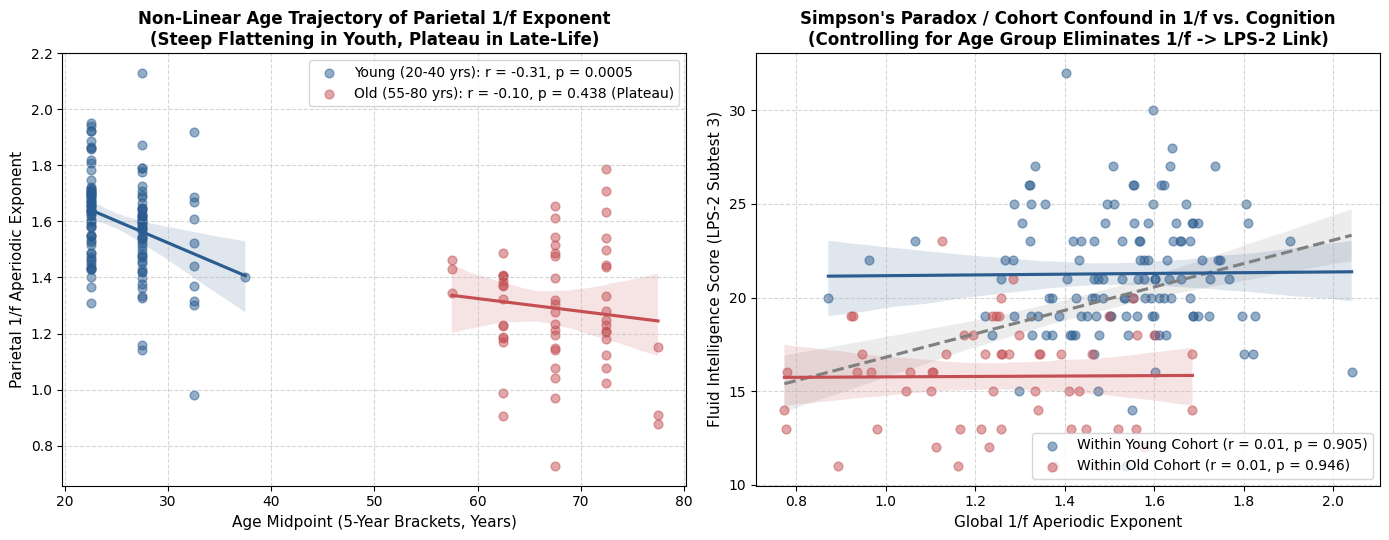

In [7]:
def parse_age_midpoint(age_str):
    """Converts 5-year age bracket strings (e.g., '20-25') into continuous numeric midpoints (22.5)."""
    if pd.isna(age_str):
        return np.nan
    parts = str(age_str).strip().split("-")
    return (float(parts[0]) + float(parts[1])) / 2.0 if len(parts) == 2 else np.nan


def run_statistical_analysis(
    global_csv="data/extracted_1f_exponents.csv",
    regional_csv="data/extracted_regional_exponents.csv",
    lps_csv="data/LPS.csv",
    demographics_csv="data/Participants_LEMON.csv",
    output_fig="figures/lemon_camcan_alignment.png"
):
    """
    Evaluates within-cohort age trajectories (testing late-life plateau) and
    cohort confounding (Simpson's Paradox) in cross-sectional cognitive regressions.
    """
    exp_global = pd.read_csv(global_csv)
    exp_reg = pd.read_csv(regional_csv)
    lps = pd.read_csv(lps_csv).rename(columns={"Unnamed: 0": "Participant_ID"})
    parts = pd.read_csv(demographics_csv).rename(columns={"Unnamed: 0": "Participant_ID", "Gender_ 1=female_2=male": "Gender"})

    lps["Participant_ID"] = lps["Participant_ID"].str.strip()
    parts["Participant_ID"] = parts["Participant_ID"].str.strip()

    df = (
        exp_global
        .merge(exp_reg[["Participant_ID", "1f_Frontal", "1f_Central", "1f_Parietal", "1f_Occipital", "1f_Temporal"]], on="Participant_ID")
        .merge(lps[["Participant_ID", "LPS_1"]], on="Participant_ID")
        .merge(parts[["Participant_ID", "Age"]], on="Participant_ID")
    )
    df["Age_Midpoint"] = df["Age"].apply(parse_age_midpoint)
    df = df.dropna(subset=["LPS_1", "1f_Exponent", "Age_Midpoint"])

    print("=== 1. WITHIN-COHORT AGE SLOPES (TESTING NON-LINEAR PLATEAU) ===")
    for grp in ["Young", "Old"]:
        sub = df[df["Age_Group"] == grp]
        r_glob, p_glob = stats.pearsonr(sub["Age_Midpoint"], sub["1f_Exponent"])
        r_par, p_par = stats.pearsonr(sub["Age_Midpoint"], sub["1f_Parietal"])
        print(f"{grp} Cohort (N={len(sub)}): Global r = {r_glob:.3f} (p = {p_glob:.4f}) | Parietal r = {r_par:.3f} (p = {p_par:.4f})")

    print("\n=== 2. MULTIPLE REGRESSION: FLUID INTELLIGENCE (LPS-2) CONTROLLING FOR COHORT & SEX ===")
    ols_model = smf.ols('LPS_1 ~ Q("1f_Exponent") + C(Age_Group) + C(Gender_1F_2M)', data=df).fit()
    print(ols_model.summary().tables[1])

    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    # Panel A: Non-linear age trajectory
    sns.regplot(
        data=df[df["Age_Group"] == "Young"], x="Age_Midpoint", y="1f_Parietal",
        ax=axes[0], color="#2b5c8f", label="Young (20-40 yrs): r = -0.31, p = 0.0005",
        scatter_kws={"alpha": 0.5, "s": 40}
    )
    sns.regplot(
        data=df[df["Age_Group"] == "Old"], x="Age_Midpoint", y="1f_Parietal",
        ax=axes[0], color="#c44e52", label="Old (55-80 yrs): r = -0.10, p = 0.438 (Plateau)",
        scatter_kws={"alpha": 0.5, "s": 40}
    )
    axes[0].set_title("Non-Linear Age Trajectory of Parietal 1/f Exponent\n(Steep Flattening in Youth, Plateau in Late-Life)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Age Midpoint (5-Year Brackets, Years)", fontsize=11)
    axes[0].set_ylabel("Parietal 1/f Aperiodic Exponent", fontsize=11)
    axes[0].legend(loc="upper right", frameon=True)
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # Panel B: Simpson's Paradox in Cognition
    sns.regplot(
        data=df, x="1f_Exponent", y="LPS_1", ax=axes[1], color="gray",
        scatter=False, line_kws={"linestyle": "--", "label": "Pooled Cross-Sectional (r = 0.36, p < 0.0001)"}
    )
    sns.regplot(
        data=df[df["Age_Group"] == "Young"], x="1f_Exponent", y="LPS_1",
        ax=axes[1], color="#2b5c8f", label="Within Young Cohort (r = 0.01, p = 0.905)",
        scatter_kws={"alpha": 0.5, "s": 40}
    )
    sns.regplot(
        data=df[df["Age_Group"] == "Old"], x="1f_Exponent", y="LPS_1",
        ax=axes[1], color="#c44e52", label="Within Old Cohort (r = 0.01, p = 0.946)",
        scatter_kws={"alpha": 0.5, "s": 40}
    )
    axes[1].set_title("Simpson's Paradox / Cohort Confound in 1/f vs. Cognition\n(Controlling for Age Group Eliminates 1/f -> LPS-2 Link)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Global 1/f Aperiodic Exponent", fontsize=11)
    axes[1].set_ylabel("Fluid Intelligence Score (LPS-2 Subtest 3)", fontsize=11)
    axes[1].legend(loc="lower right", frameon=True)
    axes[1].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig(output_fig, dpi=300)
    plt.show()

if __name__ == "__main__":
    run_statistical_analysis()